# Turtle Breakout 20 — flat-day legs with turtle exits: long after a sharp drop (A), short at a stalled peak (B)

Pre-registration: `discussions/Turtle_Breakout/022_claude_tb20_preregistration.md`. Code: `turtle_flat_legs.py`.

Signals only at the close of a FLAT day (the TB 01 turtle holds no long). **A (long):** today's return ≤ 20th percentile of the previous 365 FLAT days. **B (short):** close within 1 ATR of the 55-day high **and** |20-day return| ≤ 0.5 × its usual size.
**Exits = the turtle's:** fixed stop 2 ATR, trailing 10-day low/high, **no take-profit, no time limit**. Size = turtle (2% of HWM / 2 ATR, ≤ 3×). 6 bp per side; funding on the perpetual.
**Gates per leg** (Yahoo 2014–19, Yahoo 2020–, Binance perp): mean net R above random FLAT-day entries with the same exits, p < 0.01, and mean net return > 0.

Environment: `TB17_DATA`, `TB01_DATA_DIR`, `TB20_SYNTHETIC=1`.

In [1]:
import os, sys, json, subprocess, tempfile, warnings, platform
from dataclasses import replace
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from dotenv import load_dotenv
warnings.filterwarnings('ignore', category=RuntimeWarning)
pd.set_option('display.width', 250); pd.set_option('display.max_columns', 40)
ROOT = Path.cwd().resolve()
while ROOT != ROOT.parent and not (ROOT / 'src' / 'data_engineering').is_dir(): ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'src')); load_dotenv(ROOT / '.env')
from data_engineering.modeling import turtle_breakout as tb, turtle_reverse as tr, turtle_stocks as tk, turtle_stock_accounts as ta, turtle_btc_history as bh, turtle_flat_diag as fd, turtle_reversal1d as rv, turtle_flat_legs as fl

SYNTHETIC = os.getenv('TB20_SYNTHETIC', '0') == '1'
LP = fl.LParams(); BP = bh.BParams()
RV = replace(rv.RParams(), quantile=LP.a_quantile, lookback_flat_days=LP.a_lookback, min_flat_days=LP.a_min_flat)
P = replace(tb.Params(), min_bar_share=0.0, funding=False, fee=BP.side_cost - tb.Params().slip); RPt = replace(tr.RParams(), side_cost=BP.side_cost)
if SYNTHETIC:
    OUT = Path(tempfile.mkdtemp(prefix='tb20-')) / '20'; LP = replace(LP, n_null=2000)
    d, _ = tk.synthetic_daily(4400, seed=20, vol=0.04, gap=0.0, steps=48, drift=0.0008); d.index = pd.date_range('2014-09-17', periods=len(d), freq='D'); YH = d
    BN = YH[YH.index >= '2019-09-10'].copy(); BFUND = pd.Series(0.0001, index=BN.index)
else:
    OUT = ROOT / 'notebooks' / 'Turtle_Breakout' / '20'
    root = Path(os.environ['DERIBIT_DATA_ROOT']).parent
    YF = Path(os.environ.get('TB17_DATA', str(root / 'Stocks' / 'tb17' / 'btc_daily.parquet')))
    if not YF.exists():
        sys.path.insert(0, str(ROOT / 'tools')); import download_tb17_btc as dl; YF = dl.download(YF.parent)
    raw = pd.read_parquet(YF); raw['date'] = pd.to_datetime(raw['date']).dt.tz_localize(None).dt.normalize()
    YH = raw.set_index('date')[['open', 'high', 'low', 'close']].sort_index(); YH = YH[~YH.index.duplicated()].dropna(); YH = YH[(YH > 0).all(axis=1)]
    base = Path(os.environ['BINANCE_UM_DIR']) if os.environ.get('BINANCE_UM_DIR') else root / 'Binance'
    BDIR = Path(os.environ.get('TB01_DATA_DIR', str(base / 'long')))
    BN = rv.daily_from_1m(pd.read_parquet(BDIR / 'BTCUSDT_um_1m.parquet', columns=['open_time', 'open', 'high', 'low', 'close']))
    fp = BDIR / 'basis' / 'funding' / 'BTCUSDT_funding.parquet'
    BFUND = rv.daily_funding(tb.funding_events(pd.read_parquet(fp)) if fp.exists() else None, BN.index)
OUT.mkdir(parents=True, exist_ok=True)
env = os.environ.copy(); env['PYTHONPATH'] = str(ROOT / 'src') + os.pathsep + env.get('PYTHONPATH', '')
chk = subprocess.run([sys.executable, '-m', 'unittest', 'discover', '-s', 'tests', '-p', 'test_turtle_flat_legs.py'], cwd=str(ROOT), env=env, capture_output=True, text=True)
print(chk.stderr.strip().splitlines()[-1]); assert chk.returncode == 0
print('Yahoo', YH.index[0].date(), '->', YH.index[-1].date(), '| Binance daily', BN.index[0].date(), '->', BN.index[-1].date())
print(json.dumps(fl.registration(LP), indent=1))

OK
Yahoo 2014-09-17 -> 2026-10-27 | Binance daily 2020-01-01 -> 2026-10-23
{
 "stop_atr": 2.0,
 "trail_n": 10,
 "atr_n": 20,
 "risk_frac": 0.02,
 "pos_cap": 3.0,
 "side_cost": 0.0006,
 "a_quantile": 0.2,
 "a_lookback": 365,
 "a_min_flat": 100,
 "b_high_n": 55,
 "b_atr_band": 1.0,
 "b_flat_sd": 0.5,
 "b_sd_lookback": 365,
 "n_null": 10000,
 "p_max": 0.01,
 "seed": 20261101,
 "start_equity": 100000.0,
 "status": "PREREGISTERED_TB022",
 "version": "TB20-0.1.0",
 "exits": "turtle: fixed 2 ATR + 10-day trailing, no take-profit, no time limit",
 "gates": "per leg x {Yahoo 2014-19, Yahoo 2020-, Binance perp}: mean net R > random FLAT-day entries (same exits), p < 0.01, and mean net return > 0; leg EDGE if all three pass"
}


## 1. Turtle state, signals, legs and the random-entry pools

In [2]:
def build(daily, funding):
    W = bh.run_window(daily, str(daily.index[0].date()), None, P, RPt, ta.AParams(), 0, np.random.default_rng(0))
    TRl = W['trades'].query("kind == 'long'").copy(); TRl.loc[TRl.open_at_end, 'exit'] = daily.index[-1] + pd.Timedelta(days=1)
    state = fd.turtle_state(daily.index, TRl, W['long'].index[0]); flat = (state == 'flat'); r = np.log(daily.close).diff()
    s = {'daily': daily, 'funding': funding, 'flat': flat, 'r': r, 'turtle': W['long']}
    s['sig'] = {'A': rv.signals(r, flat, RV), 'B': fl.signals_b(daily, flat, LP)}
    s['side'] = {'A': 1, 'B': -1}
    s['T'], s['E'], s['pool'] = {}, {}, {}
    for leg in ('A', 'B'):
        s['T'][leg], s['E'][leg] = fl.simulate_leg(daily, s['sig'][leg], s['side'][leg], LP, funding)
        s['pool'][leg] = fl.pool(daily, flat & r.notna(), s['side'][leg], LP, funding)
    return s
S = {'yahoo': build(YH, None), 'binance': build(BN, BFUND)}
for k, s in S.items():
    print(k, {leg: (int(s['sig'][leg].sum()), len(s['T'][leg])) for leg in ('A', 'B')}, '(signals, trades)', '| FLAT days', int(s['flat'].sum()))

yahoo {'A': (488, 322), 'B': (26, 18)} (signals, trades) | FLAT days 2578
binance {'A': (273, 175), 'B': (28, 17)} (signals, trades) | FLAT days 1471


## 2. Decision

In [3]:
def cut(T, a, b):
    return T[(T.entry >= pd.Timestamp(a)) & (T.entry <= pd.Timestamp(b))] if len(T) else T
WIN = {'yahoo 2014-19': ('yahoo', '2014-01-01', '2019-12-31'), 'yahoo 2020-': ('yahoo', '2020-01-01', '2100-01-01'), 'binance': ('binance', '2019-01-01', '2100-01-01')}
DEC = {}
for leg in ('A', 'B'):
    DEC[leg] = {}
    for j, (w, (src, a, b)) in enumerate(WIN.items()):
        DEC[leg][w] = fl.gate(cut(S[src]['T'][leg], a, b), cut(S[src]['pool'][leg], a, b), LP, LP.seed + 10 * j + (leg == 'B'))
    DEC[leg]['verdict'] = 'EDGE' if all(DEC[leg][w]['pass'] for w in WIN) else 'NO_EDGE'
print(json.dumps(DEC, indent=1, default=float))

{
 "A": {
  "yahoo 2014-19": {
   "trades": 125,
   "mean_R": 0.33386354025066955,
   "null_mean_R": 1.0755687958297229,
   "null_sd": 0.3622954462631616,
   "p": 0.9912008799120088,
   "mean_ret_pct": 3.99819018309674,
   "win_rate": 0.176,
   "median_hold_days": 1.0,
   "share_R_ge_3": 0.048,
   "pass": false
  },
  "yahoo 2020-": {
   "trades": 197,
   "mean_R": 0.038177898944809455,
   "null_mean_R": 0.4270954963009515,
   "null_sd": 0.15401800142286476,
   "p": 0.9976002399760024,
   "mean_ret_pct": 0.7079763881821372,
   "win_rate": 0.14213197969543148,
   "median_hold_days": 1.0,
   "share_R_ge_3": 0.02030456852791878,
   "pass": false
  },
  "binance": {
   "trades": 174,
   "mean_R": 0.05193723550280464,
   "null_mean_R": 0.2386842859596984,
   "null_sd": 0.1312405145545801,
   "p": 0.9277072292770723,
   "mean_ret_pct": 0.5331167695151253,
   "win_rate": 0.15517241379310345,
   "median_hold_days": 2.0,
   "share_R_ge_3": 0.028735632183908046,
   "pass": false
  },
  "verdict"

## 3. Reported: trades, exits, regimes, years

In [4]:
for src in ('yahoo', 'binance'):
    for leg in ('A', 'B'):
        T = S[src]['T'][leg]
        if not len(T):
            print(src, leg, 'no trades'); continue
        T = T.assign(regime=[bh.regime_of(t) for t in T.entry], year=T.entry.dt.year)
        print(f"{src} leg {leg}: {len(T)} trades, hold days median {T.hold_days.median():.0f} (p90 {T.hold_days.quantile(.9):.0f}), exits {T.reason.value_counts().to_dict()}, "
              f"top-5 share of R {T.R.nlargest(5).sum() / T.R.sum() if T.R.sum() else np.nan:.2f}")
        display(T.groupby('regime' if src == 'yahoo' else 'year').agg(trades=('R', 'size'), mean_R=('R', 'mean'), sum_R=('R', 'sum'), win=('ret', lambda x: (x > 0).mean()),
                                                                     mean_ret_pct=('ret', lambda x: 100 * x.mean()), hold=('hold_days', 'median')).round(3))

yahoo leg A: 322 trades, hold days median 1 (p90 21), exits {'stop': 312, 'gap': 10}, top-5 share of R 0.95


,trades,mean_R,sum_R,win,mean_ret_pct,hold
regime,,,,,,
after the 2025 top,40,-0.130,-5.214,0.125,-0.938,1.0
base 2015,11,0.579,6.372,0.273,3.856,3.0
bear 2018,41,-0.072,-2.940,0.098,-1.047,1.0
bear 2022,41,-0.069,-2.811,0.098,-0.646,1.0
bull 2015-17,44,0.912,40.120,0.295,11.729,2.0
bull 2019-21,79,0.204,16.094,0.152,2.439,2.0
bull 2023-25,66,-0.036,-2.367,0.136,-0.076,1.0


yahoo leg B: 18 trades, hold days median 2 (p90 15), exits {'stop': 18}, top-5 share of R -0.65


,trades,mean_R,sum_R,win,mean_ret_pct,hold
regime,,,,,,
after the 2025 top,2,-0.147,-0.294,0.000,-0.803,1.5
bear 2022,2,0.125,0.250,0.500,1.216,10.5
bull 2015-17,1,-0.042,-0.042,0.000,-0.277,1.0
bull 2019-21,9,-0.106,-0.957,0.111,-1.095,2.0
bull 2023-25,4,0.018,0.071,0.250,-0.058,6.0


binance leg A: 175 trades, hold days median 2 (p90 21), exits {'stop': 174, 'end': 1}, top-5 share of R 3.24


,trades,mean_R,sum_R,win,mean_ret_pct,hold
year,,,,,,
2020,4,1.966,7.863,0.500,16.110,13.5
2021,32,0.111,3.552,0.188,1.855,2.0
2022,35,-0.053,-1.849,0.143,-0.353,1.0
2023,16,0.418,6.692,0.125,1.740,3.5
2024,27,-0.022,-0.592,0.148,-0.016,2.0
2025,33,-0.127,-4.198,0.121,-0.784,1.0
2026,28,-0.089,-2.504,0.143,-0.737,1.0


binance leg B: 17 trades, hold days median 2 (p90 16), exits {'stop': 17}, top-5 share of R -0.57


,trades,mean_R,sum_R,win,mean_ret_pct,hold
year,,,,,,
2020,3,-0.081,-0.242,0.333,-0.738,2.0
2021,6,-0.091,-0.544,0.000,-1.154,1.5
2022,2,0.094,0.187,0.500,1.067,10.5
2023,1,-0.067,-0.067,0.000,-0.436,1.0
2024,2,-0.235,-0.471,0.000,-1.942,7.5
2025,1,0.339,0.339,1.000,1.863,20.0
2026,2,-0.150,-0.301,0.000,-0.843,1.5


## 4. Accounts: turtle, legs and combinations (equal capital per sleeve)

yahoo


,cagr,max_dd,calmar,sharpe,vol
turtle,0.299234,-0.245543,1.218664,1.222592,0.157899
A,0.079568,-0.262233,0.303426,0.624357,0.091235
B,-0.001663,-0.042586,-0.039046,-0.086301,0.012409
turtle+A,0.236957,-0.180962,1.309429,1.246654,0.12383
turtle+B,0.230684,-0.191065,1.207359,1.203791,0.125489
turtle+A+B,0.199664,-0.149835,1.332564,1.219345,0.107753
hold,0.560179,-0.83399,0.671685,0.836645,0.547201


daily correlations


,turtle,A,B
turtle,1.000,0.387,-0.004
A,0.387,1.000,-0.103
B,-0.004,-0.103,1.000


binance


,cagr,max_dd,calmar,sharpe,vol
turtle,0.131232,-0.147299,0.890919,0.899321,0.100131
A,0.022985,-0.209179,0.109882,0.235717,0.080029
B,-0.003361,-0.041758,-0.080488,-0.144358,0.015276
turtle+A,0.084767,-0.114784,0.738491,0.750858,0.078874
turtle+B,0.075809,-0.094192,0.804843,0.840906,0.062234
turtle+A+B,0.05983,-0.084867,0.704985,0.715613,0.058383
hold,0.378539,-0.766696,0.493727,0.698238,0.500136


daily correlations


,turtle,A,B
turtle,1.000,0.450,-0.007
A,0.450,1.000,-0.152
B,-0.007,-0.152,1.000


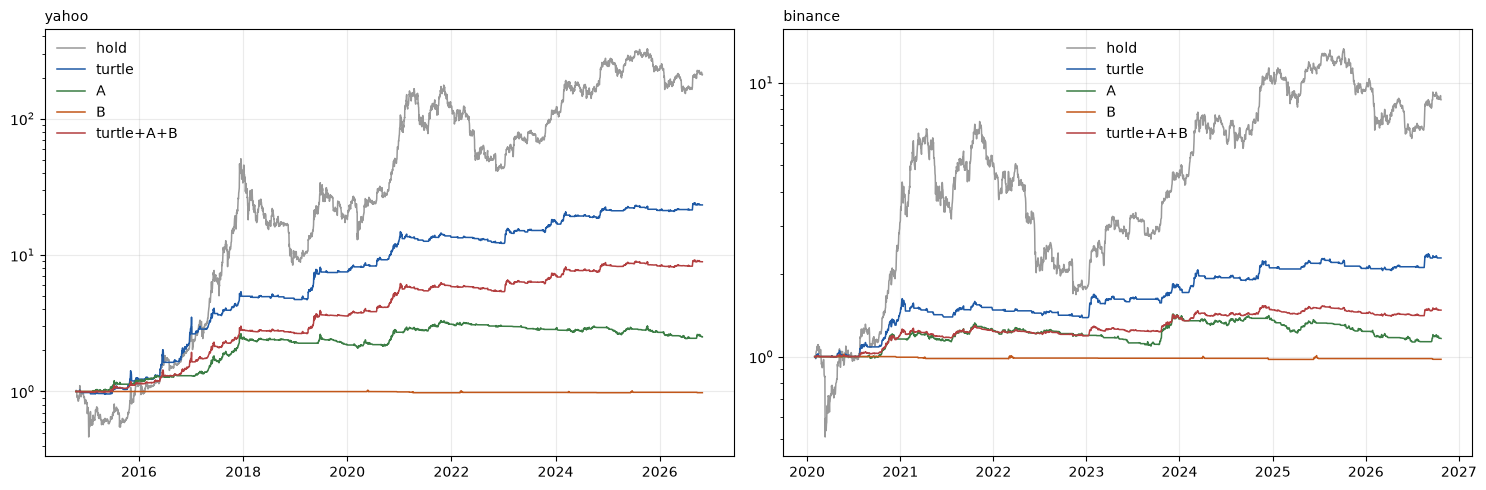

In [5]:
ACC = {}
for src in ('yahoo', 'binance'):
    s = S[src]; tur = s['turtle']; idx = tur.index
    curves = {'turtle': tur / tur.iloc[0]}
    for leg in ('A', 'B'):
        e = s['E'][leg].reindex(idx).ffill(); curves[leg] = e / e.iloc[0]
    curves['turtle+A'] = (curves['turtle'] + curves['A']) / 2; curves['turtle+B'] = (curves['turtle'] + curves['B']) / 2
    curves['turtle+A+B'] = (curves['turtle'] + curves['A'] + curves['B']) / 3
    h = s['daily'].close.reindex(idx); curves['hold'] = h / h.iloc[0]
    ACC[src] = curves
    m = pd.DataFrame({k: tk.metrics(v * 1e5, 1e5) for k, v in curves.items()}).T
    lr = pd.DataFrame({k: np.log(curves[k]).diff() for k in ('turtle', 'A', 'B')})
    print(src); display(m[['cagr', 'max_dd', 'calmar', 'sharpe', 'vol']].round(3)); print('daily correlations'); display(lr.corr().round(3))
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, src in zip(axes, ('yahoo', 'binance')):
    for k, col in (('hold', '0.6'), ('turtle', '#1f5aa6'), ('A', '#3a7d44'), ('B', '#c2571a'), ('turtle+A+B', '#b33f40')):
        ax.plot(ACC[src][k].index, ACC[src][k], color=col, label=k, lw=1.1)
    ax.set_yscale('log'); ax.legend(frameon=False); ax.grid(alpha=0.25); ax.set_title(src, loc='left', fontsize=10)
plt.tight_layout(); plt.show()

## 5. Save

In [6]:
for src in ('yahoo', 'binance'):
    for leg in ('A', 'B'):
        S[src]['T'][leg].to_csv(OUT / f'20_trades_{src}_{leg}.csv', index=False)
    pd.DataFrame(ACC[src]).to_csv(OUT / f'20_accounts_{src}.csv')
(OUT / '20_decision.json').write_text(json.dumps({'decision': DEC, 'registration': fl.registration(LP), 'synthetic': SYNTHETIC}, indent=1, default=float))
git = subprocess.run(['git', 'rev-parse', '--short', 'HEAD'], cwd=str(ROOT), capture_output=True, text=True).stdout.strip()
(OUT / '20_manifest.json').write_text(json.dumps({'version': fl.VERSION, 'git': git, 'python': platform.python_version(), 'created_utc': pd.Timestamp.now('UTC').isoformat(), 'synthetic': SYNTHETIC}, indent=1))
print('saved to', OUT); print({leg: DEC[leg]['verdict'] for leg in DEC})

saved to D:\Projects\deribit_market_data\notebooks\Turtle_Breakout\20
{'A': 'NO_EDGE', 'B': 'NO_EDGE'}
